# Eniac · Lohnen sich die Rabatte?

**Team Discount Detectives** – Walter, Miguel und Tim Aßmann · WBS Coding School, Weiterbildung Data Analysis and AI · November 2026

Dieses Notebook enthält den **finalen Code** hinter unserer Präsentation für den CEO von Eniac. Jede Zahl und jedes Diagramm der Folien entsteht hier Schritt für Schritt aus den Rohdaten.

**Die Frage des CEO:** Lohnen sich Eniacs Rabatte?

| Teilfrage | Antwort |
|---|---|
| 1. Bringen Rabatte Umsatz? | Ja, aber nicht überall. |
| 2. Kosten Rabatte uns Umsatz und Ruf? | Den Ruf nicht, aber Geld an der falschen Stelle. |

**Gesamtantwort:** Wir verlieren kein Geld. Aber wir verpassen Geld, das wir noch nicht verdienen.

**Aufbau**
1. Daten laden
2. Bereinigung
3. Arbeitstabelle
4. Teilfrage 1 · Bringen Rabatte Umsatz?
5. Teilfrage 2 · Kosten Rabatte uns Umsatz und Ruf?
6. Empfehlung
7. Anhang
8. Abgleich mit der Präsentation

**Zur Entstehung:** Den Code habe ich auf Basis der ersten Fassungen von Walter und Miguel überarbeitet und vereinheitlicht. Die Regeln für die Bereinigung haben wir gemeinsam im Team festgelegt. Die Diagramme hier sind die statischen Fassungen; die animierten GIFs der Präsentation entstehen in eigenen Skripten nach demselben Prinzip (Bild für Bild mit matplotlib, zusammengesetzt mit Pillow).

## 0 · Startzelle
Bibliotheken, Farben und zwei kleine Hilfsfunktionen. Die Farben haben eine feste Bedeutung, die in allen Diagrammen gleich bleibt: **Orange = Umsatz**, **Rot = Rabatt**, **Blau = Apple** im Markenvergleich.

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

# Ordner mit den vier Rohdateien (orders.csv, orderlines.csv, products.csv, brands.csv)
DATEN = os.environ.get("ENIAC_DATEN", "./daten/")

# Farben: dunkler Hintergrund, kontrastreiche Farben mit fester Bedeutung
BG, FG, GRAU = "#0A0A0C", "#EDEDF0", "#8A8F99"
ORANGE, ROT, BLAU, LINIE = "#F28E2B", "#E15759", "#4FA3E0", "#2A2D35"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": FG, "axes.labelcolor": GRAU, "xtick.color": FG, "ytick.color": FG,
    "axes.edgecolor": LINIE, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 12, "axes.titlesize": 16, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})
pd.set_option("display.max_columns", 12)

def de(zahl, stellen=1):
    # Zahl im deutschen Format: 1.234,5
    return f"{zahl:,.{stellen}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def balken_abrunden(ax, radius_px=10, richtung="oben"):
    # Rundet nur das Ende der Balken ab (oben bzw. rechts), der Fuß bleibt eckig.
    # Erst aufrufen, wenn die Achsengrenzen feststehen.
    ax.figure.canvas.draw()
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    box = ax.get_window_extent()
    rx = radius_px * abs(x1 - x0) / box.width
    ry = radius_px * abs(y1 - y0) / box.height
    for balken in list(ax.patches):
        x, y, b, h = balken.get_x(), balken.get_y(), balken.get_width(), balken.get_height()
        farbe = balken.get_facecolor()
        balken.remove()
        r = min(rx, b / 2) if richtung == "oben" else min(rx, b)
        ax.add_patch(FancyBboxPatch((x, y), b, h, boxstyle=f"round,pad=0,rounding_size={r}",
                                    mutation_aspect=ry / rx, fc=farbe, ec="none"))
        if richtung == "oben":
            ax.add_patch(Rectangle((x, y), b, min(h, ry * r / rx), fc=farbe, ec="none"))
        else:
            ax.add_patch(Rectangle((x, y), min(b, r), h, fc=farbe, ec="none"))

## 1 · Daten laden
Vier Tabellen von Eniac, Januar 2017 bis März 2018:
- `orders`: eine Zeile pro Bestellung (Datum, bezahlte Summe, Status)
- `orderlines`: eine Zeile pro Artikel in einer Bestellung (SKU, Menge, Stückpreis)
- `products`: der Produktkatalog (SKU, Name, Listenpreis)
- `brands`: Markenkürzel (die ersten drei Zeichen der SKU) und Markenname

In [2]:
orders = pd.read_csv(DATEN + "orders.csv")
orderlines = pd.read_csv(DATEN + "orderlines.csv")
products = pd.read_csv(DATEN + "products.csv")
brands = pd.read_csv(DATEN + "brands.csv")

for name, tabelle in {"orders": orders, "orderlines": orderlines,
                      "products": products, "brands": brands}.items():
    print(f"{name:<11} {len(tabelle):>8,} Zeilen".replace(",", "."))

orders       226.909 Zeilen
orderlines   293.983 Zeilen
products      19.326 Zeilen
brands           187 Zeilen


## 2 · Bereinigung

### 2.1 · orders: nur abgeschlossene Bestellungen
Warenkörbe, Stornos und offene Zahlungen sind keine Käufe. Als Umsatz zählt nur, was den Status „Completed“ hat.

In [3]:
print(orders["state"].value_counts(), "\n")

orders_cl = orders[orders["state"] == "Completed"].copy()
orders_cl["created_date"] = pd.to_datetime(orders_cl["created_date"])

print("Bestellungen vorher:  ", de(len(orders), 0))
print("Bestellungen nachher: ", de(len(orders_cl), 0))

state
Shopping Basket    117809
Completed           46605
Place Order         40883
Pending             14379
Cancelled            7233
Name: count, dtype: int64 

Bestellungen vorher:   226.909
Bestellungen nachher:  46.605


### 2.2 · orderlines: Preise mit zwei Punkten reparieren
Der Stückpreis steht als Text in der Tabelle. Ein Teil der Preise hat zwei Punkte, zum Beispiel `1.137.99`. Bevor wir etwas ändern, prüfen wir das Muster: Haben **alle** diese Preise das Format `1.234.56`? Dann ist der erste Punkt ein Tausenderpunkt und kann sicher entfernt werden.

Löschen wäre hier die schlechtere Wahl: Diese Zeilen sind fast ausschließlich teure Geräte. Ohne sie gingen rund 46 % des Umsatzes verloren.

In [4]:
preis_text = orderlines["unit_price"].astype(str)
zwei_punkte = preis_text.str.count(r"\.") == 2

print("Preise mit zwei Punkten:", de(zwei_punkte.sum(), 0))
print("Alle im Format 1.234.56:", preis_text[zwei_punkte].str.fullmatch(r"\d+\.\d{3}\.\d{2}").all())
print("Beispiele:", preis_text[zwei_punkte].head(3).tolist())

Preise mit zwei Punkten: 36.169
Alle im Format 1.234.56: True
Beispiele: ['1.137.99', '2.565.99', '3.278.99']


In [5]:
# Ersten Punkt entfernen (nur bei den Preisen mit zwei Punkten), dann in Zahlen umwandeln
orderlines["unit_price"] = preis_text.where(~zwei_punkte,
                                            preis_text.str.replace(".", "", n=1, regex=False)).astype(float)

# Nur Zeilen, die zu abgeschlossenen Bestellungen gehören
orderlines_cl = orderlines[orderlines["id_order"].isin(orders_cl["order_id"])].copy()
orderlines_cl["date"] = pd.to_datetime(orderlines_cl["date"])

print("Bestellzeilen vorher:  ", de(len(orderlines), 0))
print("Bestellzeilen nachher: ", de(len(orderlines_cl), 0))

Bestellzeilen vorher:   293.983
Bestellzeilen nachher:  62.103


### 2.3 · products: Duplikate und kaputte Preise
Im Katalog gibt es drei Probleme:
1. **Duplikate:** Viele Produkte stehen mehrfach in der Tabelle. Jede SKU soll nur einmal vorkommen.
2. **Kaputte Preise:** Auch hier gibt es Preise mit mehreren Punkten oder mit drei Nachkommastellen.
3. **Lücken:** Einige Produkte haben keine Beschreibung, keinen Typ oder keinen Preis.

Walters Idee, um die Preisformate sichtbar zu machen: Jede Ziffer wird durch eine 9 ersetzt. Aus `29.99` wird `99.99`, aus `1.568.206` wird `9.999.999`. So sieht man sofort, welche Formate es gibt.

In [6]:
produkte = products.drop_duplicates(subset="sku").copy()
print("Produkte vorher:", de(len(products), 0), "· ohne Duplikate:", de(len(produkte), 0), "\n")

# Walters Methode: Formate sichtbar machen
formate = produkte["price"].astype(str).str.replace(r"\d", "9", regex=True)
formate.value_counts().head(8)

Produkte vorher: 19.326 · ohne Duplikate: 10.579 



price
99.99        3436
999.99       2035
9999         1132
999          1112
99            920
9999.99       658
99.9          347
9.999.999     229
Name: count, dtype: int64

Anders als in `orderlines` lässt sich hier nicht eindeutig sagen, wo der Tausenderpunkt hingehört. Eine Tastatur für 1.568 € ist vermutlich eine Tastatur für 156,80 €. Wir haben uns im Team deshalb entschieden, diese Preise **zu löschen statt zu reparieren** (Miguels Fassung): Ein fehlender Preis ist sichtbar, ein falsch reparierter Preis verfälscht den Rabatt, ohne dass es auffällt.

Die Spalte `promo_price` ist zu über 90 % kaputt und wird nicht gebraucht. Den Rabatt berechnen wir aus Listenpreis und tatsächlich bezahltem Preis.

In [7]:
preis = produkte["price"].astype(str)
kaputt = (preis.str.count(r"\.") > 1) | preis.str.fullmatch(r"\d+\.\d{3}")
print("Kaputte Preise:", de(kaputt.sum(), 0))

produkte = produkte[~kaputt].drop(columns="promo_price")
produkte["desc"] = produkte["desc"].fillna("Keine Beschreibung")
produkte["type"] = produkte["type"].fillna(produkte["type"].mode()[0])
produkte["price"] = pd.to_numeric(produkte["price"])
produkte = produkte.dropna(subset=["price"])          # Produkte ohne Preis

print("Produkte nachher:", de(len(produkte), 0))

Kaputte Preise: 542
Produkte nachher: 9.992


### 2.4 · Zusammenführen und Rabatt berechnen
Wir verbinden die Bestellzeilen über die SKU mit dem Katalog. Zeilen, deren Produkt nicht im bereinigten Katalog steht, haben keinen Listenpreis und fallen weg.

**Rabatt in Prozent** je Bestellzeile: `1 − bezahlter Preis / Listenpreis`. Wenige Artikel wurden über dem Listenpreis verkauft. Ihr Rabatt wird auf 0 gesetzt, damit sie den Durchschnitt nicht nach unten ziehen.

In [8]:
basis = orderlines_cl.merge(produkte[["sku", "name", "price"]], on="sku", how="inner")
print("Bestellzeilen mit Listenpreis:", de(len(basis), 0),
      f"({de((1 - len(basis) / len(orderlines_cl)) * 100)} % ohne Katalogpreis entfernt)")

basis["rabatt"] = (1 - basis["unit_price"] / basis["price"]).clip(lower=0)
print("Zeilen über Listenpreis (Rabatt auf 0 gesetzt):", de((basis["unit_price"] > basis["price"]).sum(), 0))
print("Median-Rabatt:", de(basis["rabatt"].median() * 100), "%")

Bestellzeilen mit Listenpreis: 60.375 (2,8 % ohne Katalogpreis entfernt)
Zeilen über Listenpreis (Rabatt auf 0 gesetzt): 1.680
Median-Rabatt: 17,1 %


## 3 · Arbeitstabelle
Jede Zeile ist ein verkaufter Artikel. Dazu kommen:
- **Umsatz** = bezahlter Preis × Menge
- **Listenumsatz** = Listenpreis × Menge (was ohne Rabatt bezahlt worden wäre)
- **Rabatt in Euro** = Listenumsatz − Umsatz. Hier bleiben die wenigen Verkäufe über Listenpreis drin, weil sie das ausgegebene Rabattgeld tatsächlich verringern.
- **Monat**, **Kategorie** und **Marke**

### Kategorien
Die Kategorie ergibt sich aus Stichwörtern im Produktnamen. Die Reihenfolge der Regeln ist wichtig: Die erste passende Regel gewinnt. Echte Apple-Geräte erkennen wir daran, dass der Name mit „Apple MacBook“, „Apple iPhone“ usw. beginnt. Danach kommt Zubehör, damit eine „Case for MacBook“ bei den Hüllen landet und nicht bei den Macs.

In [9]:
basis["umsatz"] = basis["unit_price"] * basis["product_quantity"]
basis["listenumsatz"] = basis["price"] * basis["product_quantity"]
basis["rabatt_eur"] = basis["listenumsatz"] - basis["umsatz"]
basis["monat"] = basis["date"].dt.to_period("M")

vorne = r"^(open - |\(open\) |like new - )?"
regeln = [
    ("Service",                 r"\b(repair|replacement|installation|service|applecare|warranty|waranty)\b"),
    ("Mac",                     vorne + r"apple (macbook|imac|mac)\b"),
    ("iPhone und iPad",         vorne + r"apple (iphone|ipad)\b"),
    ("Apple Watch",             vorne + r"(apple watch|watch apple)\b"),
    ("Hüllen und Taschen",      r"\b(case|cases|sleeve|cover|bag|backpack|briefcase|housing|funda|protector|skin|film|folio|shell|tempered glass)\b"),
    ("Armbänder",               r"\b(strap|(?<!dual-)(?<!dual )band|armband|bracelet|correa|loop|belt)\b"),
    ("Speicher",                r"\b(ssd|hdd|hard drive|hard disk|drive|nas|raid|memory|ram|disk|storage|pendrive|jumpdrive|lacie|time capsule|microsd\w*|sdhc|sdxc|qnap|synology|drobo|my cloud|my passport|usb key|key|flash|datatraveler)\b"),
    ("Kabel und Strom",         r"\b(cable|adapter|hub|docks?|docking|charger|charging|battery|powerbank|power bank|powerstation|plug|usb-c|lightning|multiport)\b"),
    ("Audio",                   r"\b(headphones?|earphones?|speakers?|headsets?|beats|jbl|audio|earpods|airpods|sound)\b"),
    ("Monitore und Eingabe",    r"\b(monitor|display|keyboard|mouse|trackpad|pen|pencil|pointer|stylus|wacom|ultrasharp|dell)\b"),
    ("Netzwerk und Smart Home", r"\b(wi-fi|wifi|router|switch|repeater|extender|hue|smart|sensor|camera|drone|minidrone|thermometer|thermostat|scale|netatmo|weather)\b"),
]

def kategorie_finden(name):
    name = str(name).lower()
    for kategorie, muster in regeln:
        if re.search(muster, name):
            return kategorie
    return "Sonstiges"

basis["kategorie"] = basis["name"].apply(kategorie_finden)
basis["kategorie"].value_counts()

kategorie
Speicher                   14847
Kabel und Strom            10828
Hüllen und Taschen          8767
Sonstiges                   5676
Monitore und Eingabe        5346
iPhone und iPad             3937
Audio                       3130
Mac                         3044
Netzwerk und Smart Home     1999
Service                     1865
Apple Watch                  484
Armbänder                    452
Name: count, dtype: int64

### Marken
Die Marke steckt in den ersten drei Zeichen der SKU. Ein Sonderfall ist das Kürzel „Pack“: Darunter stehen fertig konfigurierte Pakete, zum Beispiel ein iMac mit mehr Speicher. Für diese Pakete bestimmen wir die Marke aus dem Namen (Miguels Regel): Bekannte Fremdmarken zuerst, dann Apple-Begriffe, der Rest bleibt „Pack · konfiguriert“.

In [10]:
marke_kurz = dict(zip(brands["short"], brands["long"]))
apple_worte = [" apple", "macbook", "imac", "mac mini", " mac pro", "iphone", "ipad", "ipod", "airpods"]

def marke_finden(sku, name):
    marke = marke_kurz.get(sku[:3])
    name = " " + str(name).lower() + " "
    if marke is None:
        return "Ohne Marke"
    if marke.lower() != "pack":
        return marke
    for wort, fremdmarke in [("owc", "OWC"), ("lacie", "LaCie"), ("wacom", "Wacom"), ("belkin", "Belkin")]:
        if wort in name:
            return fremdmarke
    if any(wort in name for wort in ["synology", "qnap", "newertech", "kingston"]):
        return "Pack · konfiguriert"
    if any(wort in name for wort in apple_worte):
        return "Apple"
    return "Pack · konfiguriert"

basis["marke"] = [marke_finden(s, n) for s, n in zip(basis["sku"], basis["name"])]
basis["ist_apple"] = basis["marke"] == "Apple"
print("Marken:", basis["marke"].nunique())
basis[["sku", "name", "kategorie", "marke", "price", "unit_price", "rabatt"]].head()

Marken: 180


,sku,name,kategorie,marke,price,unit_price,rabatt
0,OWC0100,OWC In-line Digital Temperature Sensor Kit HDD iMac 2011,Speicher,OWC,60.99,47.49,0.221348
1,IOT0014,iOttie Easy View 2 Car Black Support,Sonstiges,iOttie,22.95,18.99,0.172549
2,APP0700,"Apple 85W MagSafe 2 charger MacBook Pro screen Retina 15 ""(OEM)",Kabel und Strom,Apple,89.00,72.19,0.188876
3,PAC0929,"Apple iMac 27 ""Core i5 3.2GHz Retina 5K | 32GB | 2TB Drive Fusion",Mac,Apple,3209.00,2565.99,0.200377
4,CRU0039-A,(Open) Crucial 240GB SSD 7mm BX200,Speicher,Crucial,76.99,60.90,0.208988


## 4 · Teilfrage 1 · Bringen Rabatte Umsatz?

### T1.1 · Unsere Datengrundlage
Der Umsatz auf der Folie (15,9 Mio. €) ist die Summe der tatsächlich bezahlten Bestellungen aus `orders`. Die Bestellzeilen mit Listenpreis ergeben etwas weniger, weil Zeilen ohne Katalogpreis fehlen. Alle Anteile in den folgenden Abschnitten beziehen sich auf die Bestellzeilen.

In [11]:
tage = (orders_cl["created_date"].max() - orders_cl["created_date"].min()).days
print("Analysezeitraum:          ", tage, "Tage")
print("Abgeschlossene Bestellungen:", de(len(orders_cl), 0))
print("Umsatz (bezahlt):          ", de(orders_cl["total_paid"].sum() / 1e6), "Mio. €")
print("Umsatz der Bestellzeilen:  ", de(basis["umsatz"].sum() / 1e6, 2), "Mio. €")

Analysezeitraum:           437 Tage
Abgeschlossene Bestellungen: 46.605
Umsatz (bezahlt):           15,9 Mio. €
Umsatz der Bestellzeilen:   15,19 Mio. €


### T1.2 · Wie viel Rabatt geben wir?
Gezählt werden Positionen, also Bestellzeilen. Eine Position gilt als rabattiert, wenn der bezahlte Preis unter dem Listenpreis liegt.

In [12]:
rabattiert = (basis["rabatt"] > 0).sum()
print(f"{de(rabattiert, 0)} von {de(len(basis), 0)} Positionen rabattiert: {de(rabattiert / len(basis) * 100)} %")
print("Zum regulären Preis:", de((1 - rabattiert / len(basis)) * 100), "%")

56.203 von 60.375 Positionen rabattiert: 93,1 %
Zum regulären Preis: 6,9 %


### T1.3 · Monatsverlauf
Umsatz, Bestellungen und durchschnittlicher Rabatt pro Monat. Der Rabatt ist hier der einfache Durchschnitt der Rabatte aller Positionen im Monat.

November 2017: 2,89 Mio. € Umsatz, 7.106 Bestellungen, Ø Rabatt 21,5 %
Ø Rabatt über alle Monate: 21,0 %


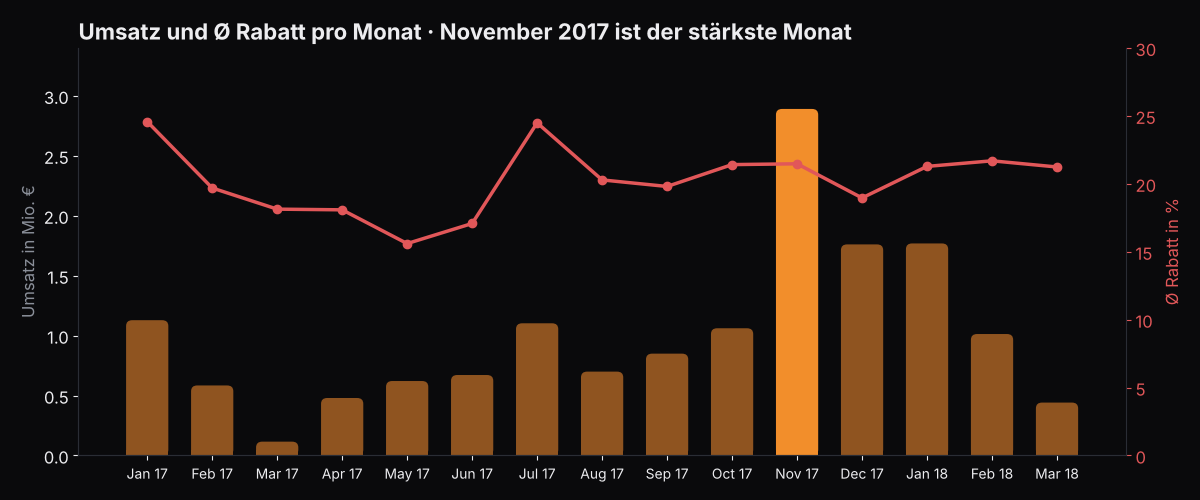

In [13]:
monate = basis.groupby("monat").agg(umsatz=("umsatz", "sum"),
                                    bestellungen=("id_order", "nunique"),
                                    rabatt=("rabatt", "mean"))

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(monate))
farben = [ORANGE if str(m) == "2017-11" else "#8F5420" for m in monate.index]
ax.bar(x, monate["umsatz"] / 1e6, color=farben, width=0.65)
ax.set_xticks(x, [m.strftime("%b %y") for m in monate.index], fontsize=10)
ax.set_ylabel("Umsatz in Mio. €")
ax.set_ylim(0, 3.4)

ax2 = ax.twinx()
ax2.plot(x, monate["rabatt"] * 100, color=ROT, lw=2.5, marker="o")
ax2.set_ylim(0, 30); ax2.set_ylabel("Ø Rabatt in %", color=ROT)
ax2.spines["right"].set_visible(True); ax2.tick_params(axis="y", colors=ROT)

ax.set_title("Umsatz und Ø Rabatt pro Monat · November 2017 ist der stärkste Monat")
balken_abrunden(ax, 6)
plt.tight_layout(); plt.show()

nov = monate.loc["2017-11"]
print(f"November 2017: {de(nov['umsatz'] / 1e6, 2)} Mio. € Umsatz, "
      f"{de(nov['bestellungen'], 0)} Bestellungen, Ø Rabatt {de(nov['rabatt'] * 100)} %")
print(f"Ø Rabatt über alle Monate: {de(basis['rabatt'].mean() * 100)} %")

### T1.4 · Womit machen wir Umsatz?
Umsatz je Kategorie. Die Macs heben wir hervor, weil sie den größten Teil tragen.

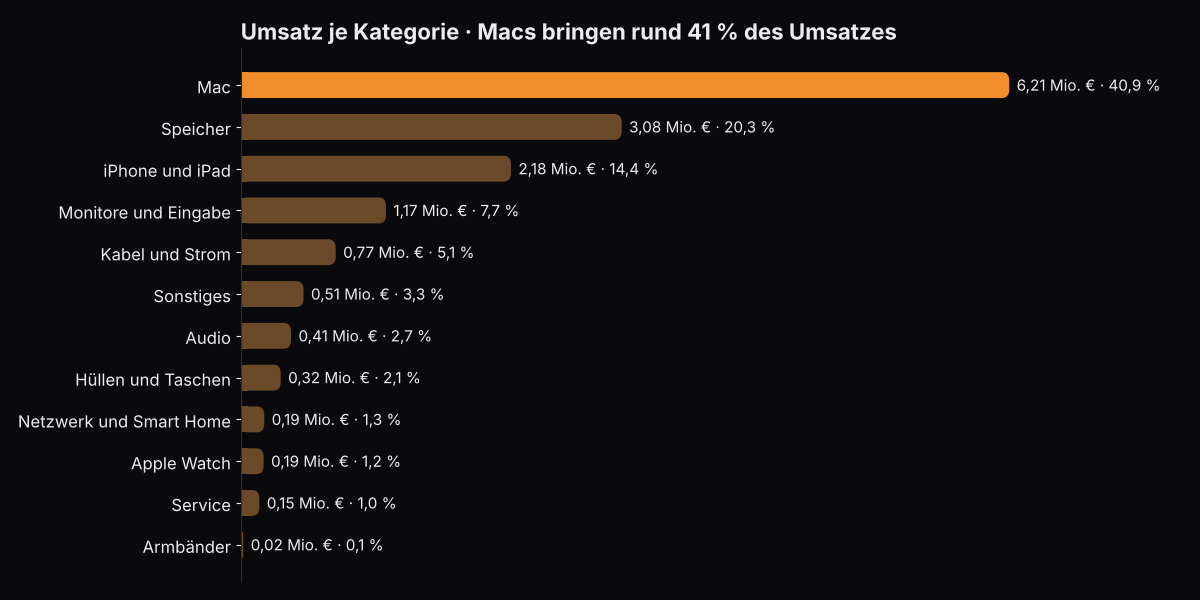

,umsatz,anteil_umsatz
kategorie,,
Mac,6205213.0,40.9
Speicher,3075686.2,20.3
iPhone und iPad,2182224.7,14.4
Monitore und Eingabe,1173044.2,7.7


In [14]:
kategorien = (basis.groupby("kategorie")
              .agg(umsatz=("umsatz", "sum"), rabatt_eur=("rabatt_eur", "sum"),
                   listenumsatz=("listenumsatz", "sum"), rabatt_mittel=("rabatt", "mean"))
              .sort_values("umsatz"))
kategorien["anteil_umsatz"] = kategorien["umsatz"] / kategorien["umsatz"].sum() * 100

fig, ax = plt.subplots(figsize=(12, 6))
farben = [ORANGE if k == "Mac" else "#6B4A2A" for k in kategorien.index]
ax.barh(kategorien.index, kategorien["umsatz"] / 1e6, color=farben, height=0.62)
for i, (u, a) in enumerate(zip(kategorien["umsatz"], kategorien["anteil_umsatz"])):
    ax.text(u / 1e6 + 0.06, i, f"{de(u / 1e6, 2)} Mio. € · {de(a)} %", va="center", fontsize=11)
ax.set_xlim(0, 7.6); ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Umsatz je Kategorie · Macs bringen rund 41 % des Umsatzes")
balken_abrunden(ax, 8, "rechts")
plt.tight_layout(); plt.show()

kategorien.sort_values("umsatz", ascending=False)[["umsatz", "anteil_umsatz"]].round(1).head(4)

**Zwischenfazit Teilfrage 1:** Ja, aber nicht überall. Fast alles wird rabattiert, und die Monate mit viel Umsatz sind die Monate mit Black Friday und Weihnachten, nicht die Monate mit dem höchsten Rabatt. Getragen wird der Umsatz von den Apple-Kernprodukten, allen voran den Macs.

## 5 · Teilfrage 2 · Kosten Rabatte uns Umsatz und Ruf?

### T2.1 · Welche Marken zählen?
Anteil am Umsatz und an den verkauften Stück für die zehn umsatzstärksten Marken. Apple macht mit wenigen Stück den größten Umsatz; bei Zubehörmarken wie OWC ist das Verhältnis umgedreht.

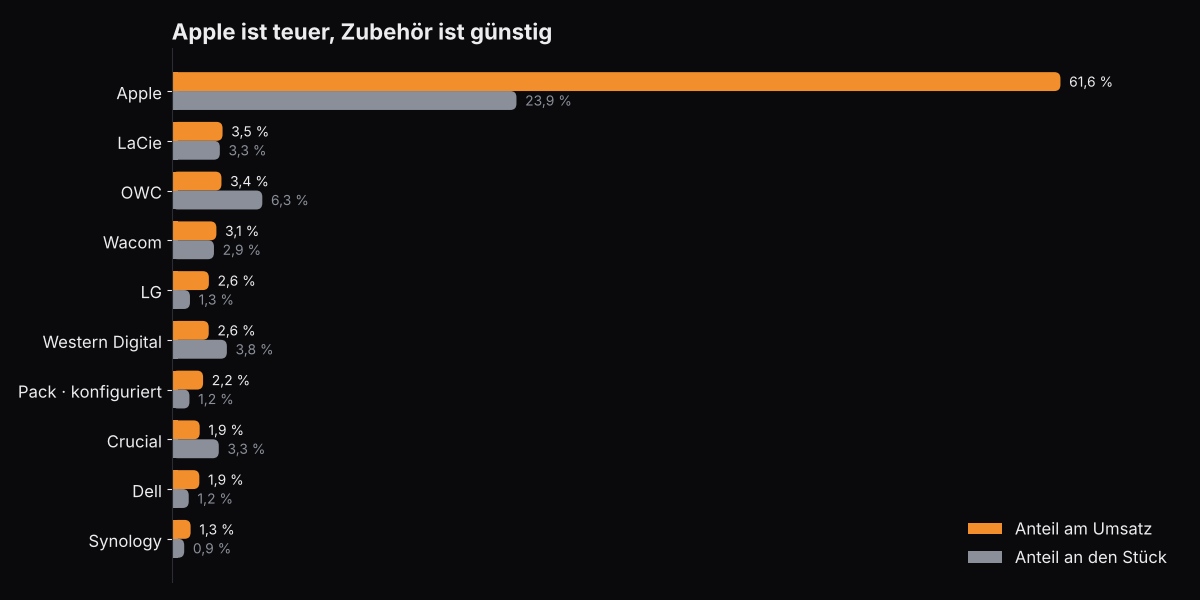

In [15]:
marken = basis.groupby("marke").agg(umsatz=("umsatz", "sum"), stueck=("product_quantity", "sum"),
                                    rabatt_eur=("rabatt_eur", "sum"), listenumsatz=("listenumsatz", "sum"))
marken["anteil_umsatz"] = marken["umsatz"] / marken["umsatz"].sum() * 100
marken["anteil_stueck"] = marken["stueck"] / marken["stueck"].sum() * 100
top = marken.sort_values("umsatz", ascending=False).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(12, 6))
y = np.arange(len(top)); h = 0.38
ax.barh(y + h / 2, top["anteil_umsatz"], height=h, color=ORANGE, label="Anteil am Umsatz")
ax.barh(y - h / 2, top["anteil_stueck"], height=h, color=GRAU, label="Anteil an den Stück")
for i, (u, s) in enumerate(zip(top["anteil_umsatz"], top["anteil_stueck"])):
    ax.text(u + 0.6, i + h / 2, f"{de(u)} %", va="center", fontsize=10)
    ax.text(s + 0.6, i - h / 2, f"{de(s)} %", va="center", fontsize=10, color=GRAU)
ax.set_yticks(y, top.index); ax.set_xlim(0, 70); ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Apple ist teuer, Zubehör ist günstig")
balken_abrunden(ax, 6, "rechts")
plt.tight_layout(); plt.show()

### T2.2 · Wo ist der Rabatt am höchsten?
Wir teilen die Produkte nach Listenpreis in fünf Klassen. Die Grenzen sind leicht zu merken und passen zu Eniac: Zubehör liegt meist unter 50 €, Macs meist über 1.000 €. Der Rabatt ist in Prozent angegeben, damit günstige und teure Produkte vergleichbar sind.

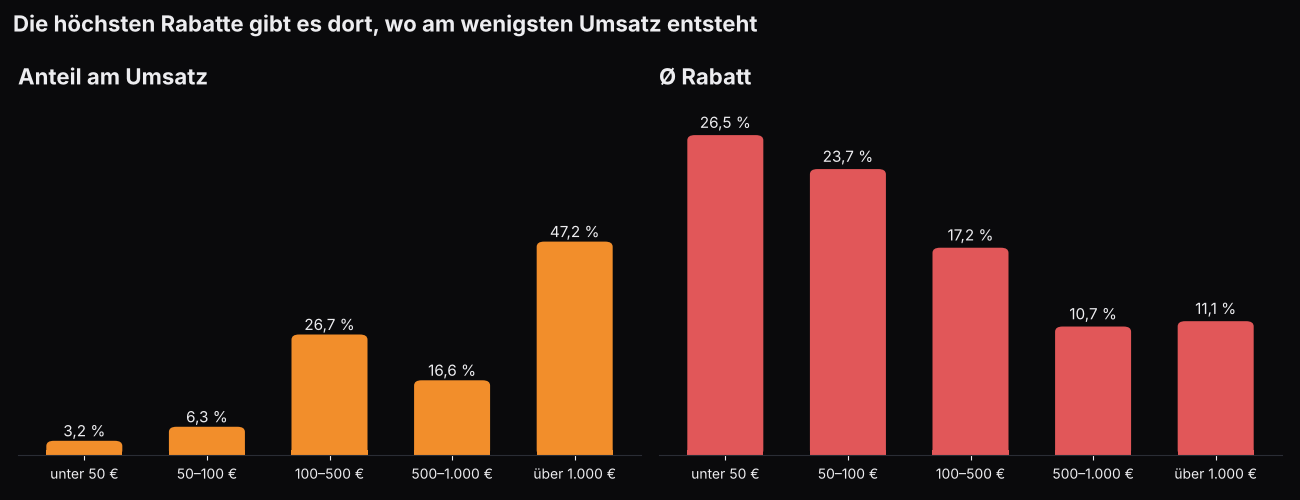

,umsatz,rabatt,anteil_umsatz
preisklasse,,,
unter 50 €,491406.62,0.265,3.236
50–100 €,961646.20,0.237,6.332
100–500 €,4051748.28,0.172,26.680
500–1.000 €,2518295.74,0.107,16.582
über 1.000 €,7163543.67,0.111,47.170


In [16]:
grenzen = [0, 50, 100, 500, 1000, float("inf")]
klassen = ["unter 50 €", "50–100 €", "100–500 €", "500–1.000 €", "über 1.000 €"]
basis["preisklasse"] = pd.cut(basis["price"], bins=grenzen, labels=klassen)

preisklassen = basis.groupby("preisklasse", observed=False).agg(umsatz=("umsatz", "sum"),
                                                                rabatt=("rabatt", "mean"))
preisklassen["anteil_umsatz"] = preisklassen["umsatz"] / preisklassen["umsatz"].sum() * 100

fig, (links, rechts) = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(klassen))
links.bar(x, preisklassen["anteil_umsatz"], color=ORANGE, width=0.62)
rechts.bar(x, preisklassen["rabatt"] * 100, color=ROT, width=0.62)
for i, (u, r) in enumerate(zip(preisklassen["anteil_umsatz"], preisklassen["rabatt"] * 100)):
    links.text(i, u + 1, f"{de(u)} %", ha="center", fontsize=11)
    rechts.text(i, r + 0.6, f"{de(r)} %", ha="center", fontsize=11)
for achse, titel, ymax in [(links, "Anteil am Umsatz", 80), (rechts, "Ø Rabatt", 30)]:
    achse.set_xticks(x, klassen, fontsize=10); achse.set_yticks([]); achse.set_ylim(0, ymax)
    achse.spines["left"].set_visible(False); achse.set_title(titel)
    balken_abrunden(achse, 6)
fig.suptitle("Die höchsten Rabatte gibt es dort, wo am wenigsten Umsatz entsteht",
             x=0.01, ha="left", fontsize=16, fontweight="bold")
plt.tight_layout(); plt.show()

preisklassen.round(3)

### T2.3 · Apple gegen alle anderen Marken
Vier Kennzahlen im direkten Vergleich. Der **Ø Rabatt** ist hier gewichtet: Rabattgeld geteilt durch Listenumsatz. So zählt ein MacBook mit seinem echten Gewicht und nicht genauso viel wie ein Kabel.

Rabattgeld Apple: 1,17 Mio. €


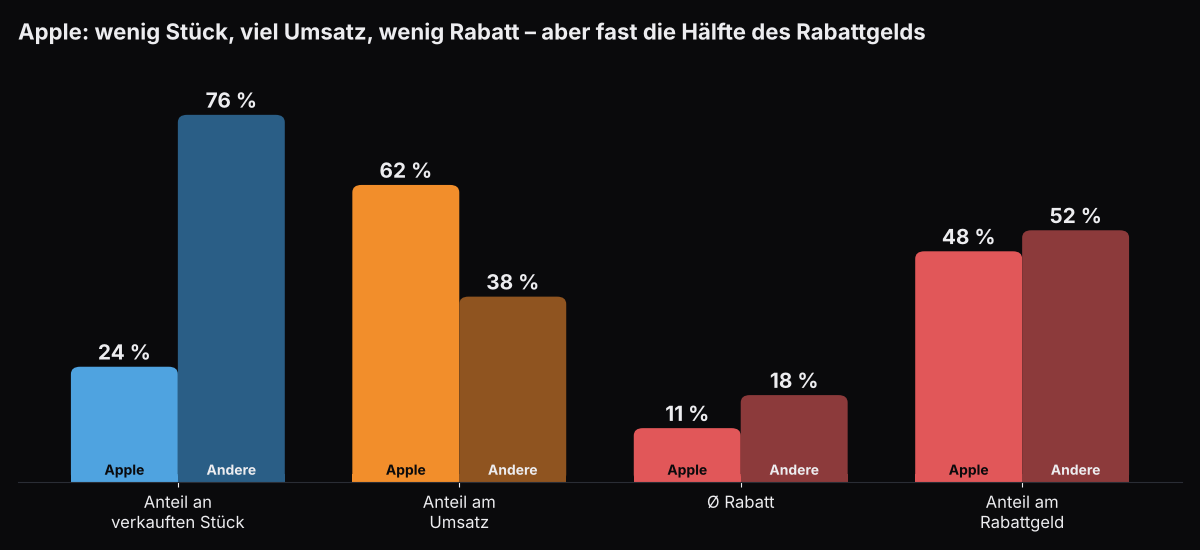

ist_apple,Apple,Andere
Anteil Stück,23.9,76.1
Anteil Umsatz,61.6,38.4
Ø Rabatt,11.2,18.0
Anteil Rabattgeld,47.8,52.2


In [17]:
vergleich = basis.groupby("ist_apple").agg(stueck=("product_quantity", "sum"), umsatz=("umsatz", "sum"),
                                           rabatt_eur=("rabatt_eur", "sum"), listenumsatz=("listenumsatz", "sum"))
vergleich.index = vergleich.index.map({True: "Apple", False: "Andere"})

kennzahlen = pd.DataFrame({
    "Anteil Stück": vergleich["stueck"] / vergleich["stueck"].sum() * 100,
    "Anteil Umsatz": vergleich["umsatz"] / vergleich["umsatz"].sum() * 100,
    "Ø Rabatt": vergleich["rabatt_eur"] / vergleich["listenumsatz"] * 100,
    "Anteil Rabattgeld": vergleich["rabatt_eur"] / vergleich["rabatt_eur"].sum() * 100,
}).T[["Apple", "Andere"]]
beschriftung = ["Anteil an\nverkauften Stück", "Anteil am\nUmsatz", "Ø Rabatt", "Anteil am\nRabattgeld"]

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(4); b = 0.38
apple_farben = [BLAU, ORANGE, ROT, ROT]
andere_farben = ["#2A5E86", "#8F5420", "#8C3A3B", "#8C3A3B"]
ax.bar(x - b / 2, kennzahlen["Apple"], width=b, color=apple_farben)
ax.bar(x + b / 2, kennzahlen["Andere"], width=b, color=andere_farben)
for i, (a, n) in enumerate(zip(kennzahlen["Apple"], kennzahlen["Andere"])):
    ax.text(i - b / 2, a + 1.5, f"{de(a, 0)} %", ha="center", fontsize=15, fontweight="bold")
    ax.text(i + b / 2, n + 1.5, f"{de(n, 0)} %", ha="center", fontsize=15, fontweight="bold")
    ax.text(i - b / 2, 1.5, "Apple", ha="center", fontsize=10, color=BG, fontweight="bold")
    ax.text(i + b / 2, 1.5, "Andere", ha="center", fontsize=10, color=FG, fontweight="bold")
ax.set_xticks(x, beschriftung, fontsize=12); ax.set_yticks([]); ax.set_ylim(0, 90)
ax.spines["left"].set_visible(False)
ax.set_title("Apple: wenig Stück, viel Umsatz, wenig Rabatt – aber fast die Hälfte des Rabattgelds")
balken_abrunden(ax, 8)
plt.tight_layout(); plt.show()

print("Rabattgeld Apple:", de(vergleich.loc["Apple", "rabatt_eur"] / 1e6, 2), "Mio. €")
kennzahlen.round(1)

**Zwischenfazit Teilfrage 2:** Den Ruf nicht, aber Geld an der falschen Stelle. Apple bekommt im Schnitt nur rund 11 % Rabatt, aber weil die Geräte teuer sind, fließt fast die Hälfte des Rabattgelds zu Apple. Die anderen Marken verkaufen dreimal so viele Geräte, bekommen mehr Rabatt in Prozent und trotzdem nur die andere Hälfte des Rabattgelds.

## 6 · Empfehlung

### E.1 · Was ist ein Prozentpunkt Apple-Rabatt wert?
Wenn Apple-Produkte zu Listenpreisen verkauft würden, wäre das der Listenumsatz. Jeder Prozentpunkt Rabatt weniger bringt bei gleicher Stückzahl 1 % dieses Betrags zusätzlich.

In [18]:
listen_apple = vergleich.loc["Apple", "listenumsatz"]
listen_andere = vergleich.loc["Andere", "listenumsatz"]
rabatt_apple = vergleich.loc["Apple", "rabatt_eur"] / listen_apple * 100     # heute, in %
rabatt_andere = vergleich.loc["Andere", "rabatt_eur"] / listen_andere * 100

pro_punkt = listen_apple / 100
print("Apple-Umsatz zu Listenpreisen:", de(listen_apple / 1e6, 2), "Mio. €")
print("Ø Apple-Rabatt heute:         ", de(rabatt_apple, 2), "%")
print("Ein Prozentpunkt Apple-Rabatt:", de(pro_punkt, 0), "€")

Apple-Umsatz zu Listenpreisen: 10,53 Mio. €
Ø Apple-Rabatt heute:          11,16 %
Ein Prozentpunkt Apple-Rabatt: 105.260 €


### E.2 · Der Puffer: Wie viele Apple-Käufer dürfen abspringen?
Senken wir den Apple-Rabatt von heute rund 11 % auf 7 %, zahlt jeder Kunde pro Gerät etwas mehr. Der Umsatz bleibt gleich, solange die Stückzahl um nicht mehr als den Kehrwert dieses Aufschlags sinkt.

Beispiel: Ein MacBook mit 1.000 € Listenpreis kostet heute rund 890 €, künftig 930 €.

In [19]:
neu = 7                                                    # neuer Apple-Rabatt in %
aufschlag = (1 - neu / 100) / (1 - rabatt_apple / 100)     # Kunde zahlt pro Gerät so viel mehr
puffer = 1 - 1 / aufschlag                                 # so viel weniger Stück sind ohne Umsatzverlust möglich
mehr_umsatz = listen_apple * (rabatt_apple - neu) / 100    # bei gleicher Stückzahl
apple_stueck = vergleich.loc["Apple", "stueck"]

print(f"Kunde zahlt pro Gerät {de((aufschlag - 1) * 100)} % mehr")
print(f"Puffer: {de(puffer * 100)} % weniger Apple-Verkäufe, also rund {de(apple_stueck * puffer, 0)} Geräte")
print(f"Mehr Umsatz bei gleicher Stückzahl: {de(mehr_umsatz / 1e6, 2)} Mio. €")

Kunde zahlt pro Gerät 4,7 % mehr
Puffer: 4,5 % weniger Apple-Verkäufe, also rund 723 Geräte
Mehr Umsatz bei gleicher Stückzahl: 0,44 Mio. €


### E.3 · Rabatt umschichten
Ein Beispielszenario für den Datenzeitraum (Januar 2017 bis März 2018): Das Geld, das wir beim Apple-Rabatt einsparen, können wir auf zwei Arten nutzen.
- **Einbehalten:** mehr Umsatz bei gleicher Stückzahl (Balken)
- **Umschichten:** bei gleichem Budget den Rabatt auf die anderen Marken erhöhen (Linie)

Andere Marken heute: 18,0 % Rabatt


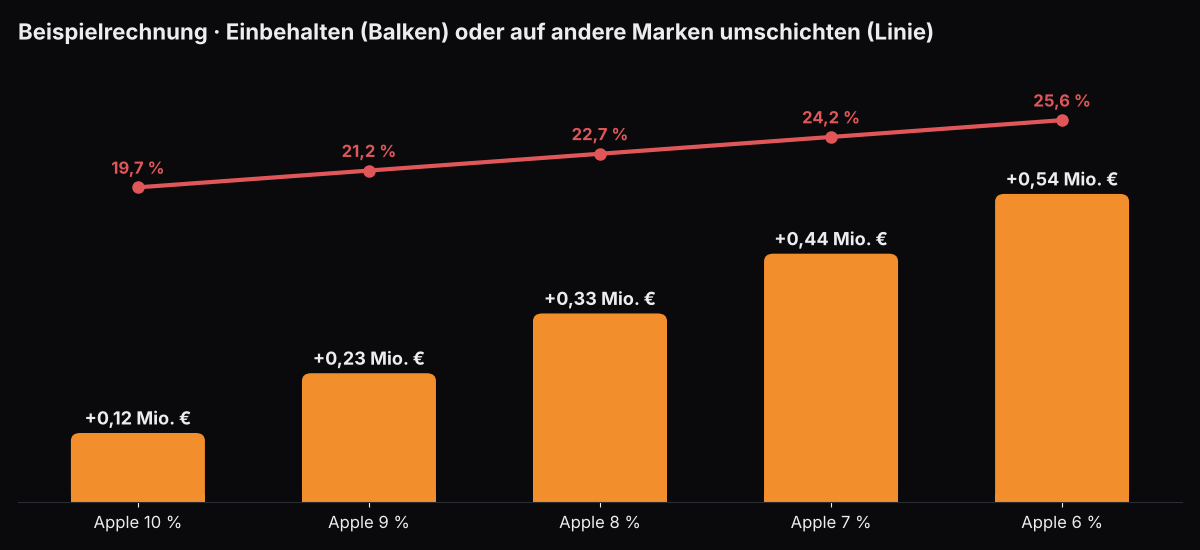

,apple_rabatt,frei_mio,andere_rabatt
0,10,0.12,19.72
1,9,0.23,21.20
2,8,0.33,22.67
3,7,0.44,24.15
4,6,0.54,25.63


In [20]:
stufen = [10, 9, 8, 7, 6]
szenario = pd.DataFrame({"apple_rabatt": stufen})
szenario["frei_mio"] = listen_apple * (rabatt_apple - szenario["apple_rabatt"]) / 100 / 1e6
szenario["andere_rabatt"] = rabatt_andere + szenario["frei_mio"] * 1e6 / listen_andere * 100

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(stufen))
ax.bar(x, szenario["frei_mio"], color=ORANGE, width=0.58)
for i, f in enumerate(szenario["frei_mio"]):
    ax.text(i, f + 0.015, f"+{de(f, 2)} Mio. €", ha="center", fontsize=13, fontweight="bold")
ax.set_xticks(x, [f"Apple {s} %" for s in stufen], fontsize=12)
ax.set_ylim(0, 0.8); ax.set_yticks([]); ax.spines["left"].set_visible(False)

ax2 = ax.twinx()
ax2.plot(x, szenario["andere_rabatt"], color=ROT, lw=3, marker="o", ms=8)
for i, r in enumerate(szenario["andere_rabatt"]):
    ax2.text(i, r + 1.2, f"{de(r)} %", ha="center", color=ROT, fontsize=12, fontweight="bold")
ax2.set_ylim(-8, 32); ax2.axis("off")

ax.set_title("Beispielrechnung · Einbehalten (Balken) oder auf andere Marken umschichten (Linie)")
balken_abrunden(ax, 8)
plt.tight_layout(); plt.show()

print(f"Andere Marken heute: {de(rabatt_andere)} % Rabatt")
szenario.round(2)

**Unsere Empfehlung**
1. **Apple-Rabatt senken.** Jeder Prozentpunkt sind rund 105.000 €.
2. **Andere Marken gezielt rabattieren.** Dort wirkt Rabatt als Kaufanreiz.
3. **Rabatt außerhalb der Saison.** Im November kaufen die Kunden ohnehin.

Weil Einkaufspreise und eine Kunden-ID fehlen, schlagen wir einen Test vor: iPads sechs Wochen lang mit 7 statt 11 % Rabatt, nicht im November, verglichen mit denselben Wochen im Vorjahr. Sinken die Verkäufe um weniger als 4,5 %, wird die Regel ausgeweitet.

## 7 · Anhang

### A4 · Ob sich ein Rabatt lohnt, hängt an der Marge
Einkaufspreise sind nicht im Datensatz. Deshalb rechnen wir Szenarien: Bei welchem Anteil der Verkäufe ist der Rabatt größer als eine angenommene Marge von 10, 20 oder 30 %? Diese Verkäufe wären Verlustgeschäfte.

In [21]:
auswahl = ["Mac", "Speicher", "iPhone und iPad", "Monitore und Eingabe", "Hüllen und Taschen"]
margen = pd.DataFrame({"Umsatzanteil %": kategorien.loc[auswahl, "anteil_umsatz"]})
for marge in [10, 20, 30]:
    margen[f"bei {marge} % Marge"] = (basis[basis["kategorie"].isin(auswahl)]
                                      .groupby("kategorie")["rabatt"]
                                      .apply(lambda r: (r > marge / 100).mean() * 100))
margen.round(1)

,Umsatzanteil %,bei 10 % Marge,bei 20 % Marge,bei 30 % Marge
kategorie,,,,
Mac,40.9,34.6,11.3,2.6
Speicher,20.3,70.2,34.0,9.9
iPhone und iPad,14.4,45.6,9.9,3.4
Monitore und Eingabe,7.7,68.3,39.6,17.9
Hüllen und Taschen,2.1,89.0,68.0,45.1


### A5 · Rabatt je Kategorie, in Prozent und in Euro
In Prozent bekommen die Macs wenig Rabatt, in Euro ist es der größte Betrag. Bei Hüllen und Taschen ist es umgekehrt.

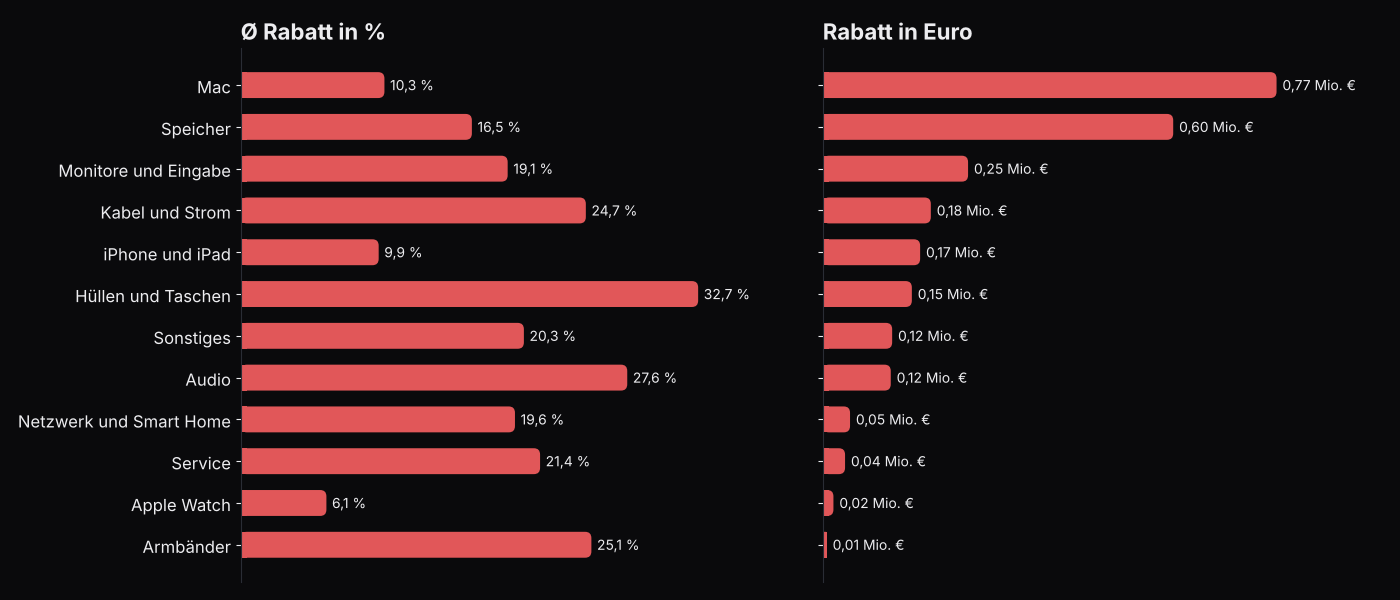

,rabatt_mittel,rabatt_eur,anteil_rabattgeld
kategorie,,,
Mac,0.103,770864.41,31.391
Hüllen und Taschen,0.327,151313.90,6.162


In [22]:
k = kategorien.sort_values("rabatt_eur")
k["anteil_rabattgeld"] = k["rabatt_eur"] / k["rabatt_eur"].sum() * 100

fig, (links, rechts) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
links.barh(k.index, k["rabatt_mittel"] * 100, color=ROT, height=0.62)
rechts.barh(k.index, k["rabatt_eur"] / 1e6, color=ROT, height=0.62)
for i, (p, e) in enumerate(zip(k["rabatt_mittel"] * 100, k["rabatt_eur"] / 1e6)):
    links.text(p + 0.4, i, f"{de(p)} %", va="center", fontsize=10)
    rechts.text(e + 0.01, i, f"{de(e, 2)} Mio. €", va="center", fontsize=10)
links.set_title("Ø Rabatt in %"); rechts.set_title("Rabatt in Euro")
links.set_xlim(0, 40); rechts.set_xlim(0, 0.95)
for achse in (links, rechts):
    achse.set_xticks([]); achse.spines["bottom"].set_visible(False)
    balken_abrunden(achse, 6, "rechts")
plt.tight_layout(); plt.show()

k.loc[["Mac", "Hüllen und Taschen"], ["rabatt_mittel", "rabatt_eur", "anteil_rabattgeld"]].round(3)

### A6 · Umsatz im Jahresverlauf je Kategorie
Gestapelte Fläche, die Macs liegen oben. Sie sind in jedem Monat die umsatzstärkste Kategorie.

Mac-Anteil am Monatsumsatz: 35 bis 72 %


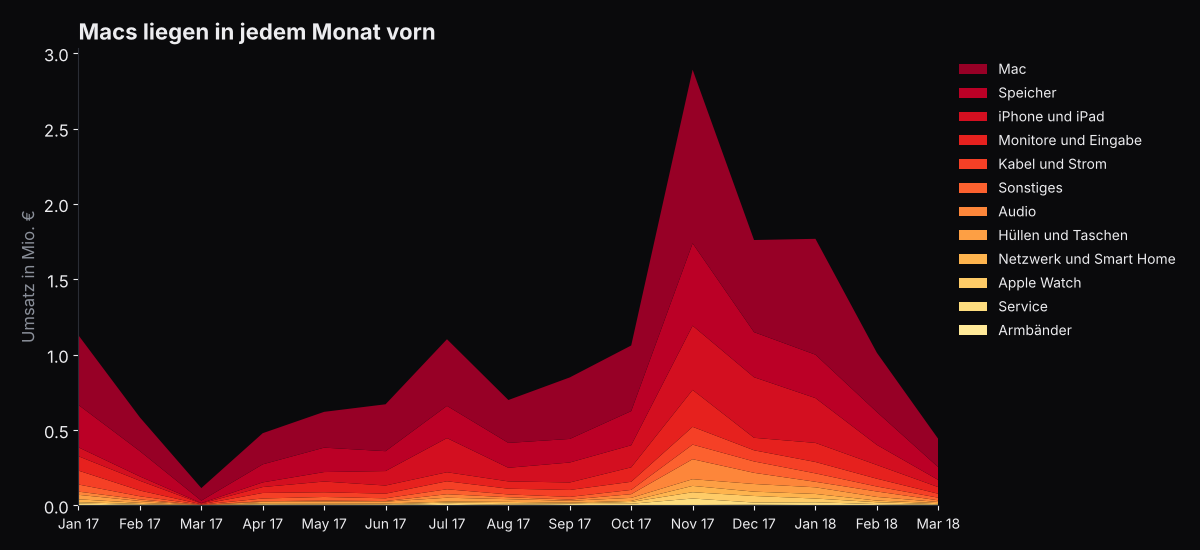

In [23]:
verlauf = basis.pivot_table(index="monat", columns="kategorie", values="umsatz", aggfunc="sum").fillna(0)
reihenfolge = verlauf.sum().sort_values().index            # kleinste unten, Mac oben
verlauf = verlauf[reihenfolge] / 1e6

farbverlauf = plt.cm.YlOrRd(np.linspace(0.15, 0.95, len(reihenfolge)))
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.stackplot(np.arange(len(verlauf)), verlauf.T.values, colors=farbverlauf, labels=reihenfolge, lw=0)
ax.set_xticks(np.arange(len(verlauf)), [m.strftime("%b %y") for m in verlauf.index], fontsize=10)
ax.set_ylabel("Umsatz in Mio. €"); ax.set_xlim(0, len(verlauf) - 1)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=10)
ax.set_title("Macs liegen in jedem Monat vorn")
plt.tight_layout(); plt.show()

mac_anteil = verlauf["Mac"] / verlauf.sum(axis=1) * 100
print(f"Mac-Anteil am Monatsumsatz: {de(mac_anteil.min(), 0)} bis {de(mac_anteil.max(), 0)} %")

### A7 · Rabattgeld je Marke
Rabatt in Euro und gewichtete Rabattquote für die zehn umsatzstärksten Marken.

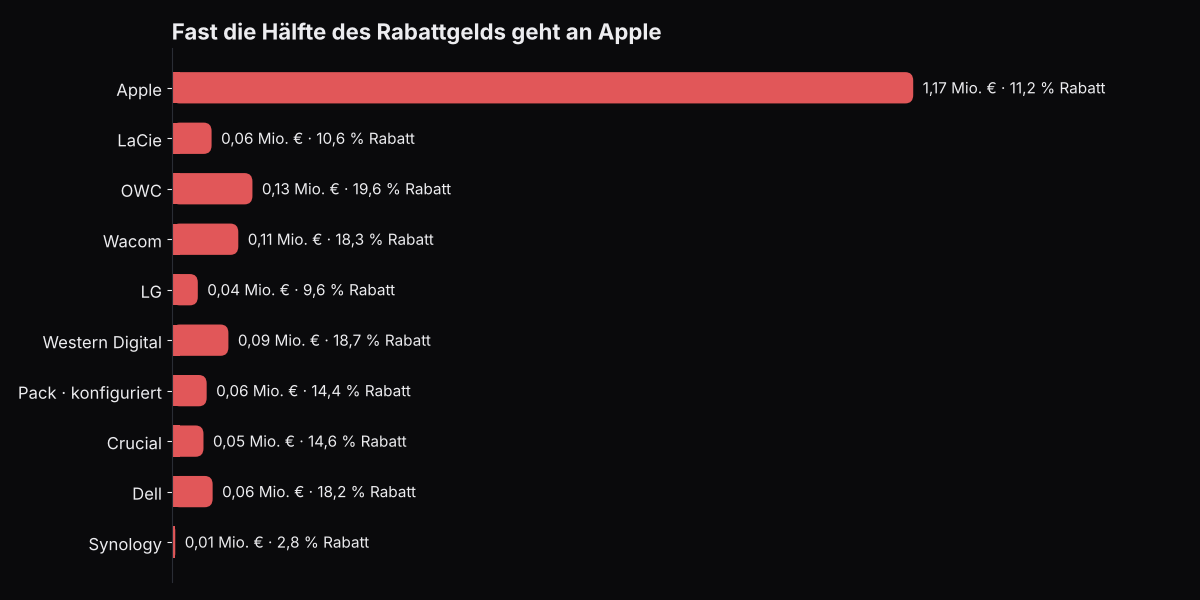

In [24]:
top10 = marken.sort_values("umsatz", ascending=False).head(10).copy()
top10["quote"] = top10["rabatt_eur"] / top10["listenumsatz"] * 100
top10 = top10.iloc[::-1]

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(top10.index, top10["rabatt_eur"] / 1e6, color=ROT, height=0.62)
for i, (e, q) in enumerate(zip(top10["rabatt_eur"] / 1e6, top10["quote"])):
    ax.text(e + 0.015, i, f"{de(e, 2)} Mio. € · {de(q)} % Rabatt", va="center", fontsize=11)
ax.set_xlim(0, 1.6); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Fast die Hälfte des Rabattgelds geht an Apple")
balken_abrunden(ax, 8, "rechts")
plt.tight_layout(); plt.show()

## 8 · Abgleich mit der Präsentation
Alle Kernzahlen der Folien, nachgerechnet. Kleine Abweichungen beim Markenvergleich (unter einem Prozentpunkt) entstehen durch Rundung und die Zuordnung einzelner Pakete zu Apple. Bei den kleineren Kategorien im Anhang (z. B. Speicher, Monitore) können die Werte leicht von den Folien abweichen, weil die Stichwortregeln für die Kategorien hier noch einmal verfeinert wurden. Die Macs sind davon nicht betroffen.

In [25]:
abgleich = pd.DataFrame([
    ("Analysezeitraum in Tagen", "437", tage),
    ("Abgeschlossene Bestellungen", "46.605", de(len(orders_cl), 0)),
    ("Umsatz in Mio. €", "15,9", de(orders_cl["total_paid"].sum() / 1e6)),
    ("Positionen rabattiert", "93 %", f"{de(rabattiert / len(basis) * 100)} %"),
    ("Umsatz November 2017 in Mio. €", "2,89", de(nov["umsatz"] / 1e6, 2)),
    ("Ø Rabatt November 2017", "21,5 %", f"{de(nov['rabatt'] * 100)} %"),
    ("Umsatz Macs in Mio. €", "6,21", de(kategorien.loc["Mac", "umsatz"] / 1e6, 2)),
    ("Anteil Macs am Umsatz", "41 %", f"{de(kategorien.loc['Mac', 'anteil_umsatz'])} %"),
    ("Apple: Anteil Stück", "24 %", f"{de(kennzahlen.loc['Anteil Stück', 'Apple'])} %"),
    ("Apple: Anteil Umsatz", "61 %", f"{de(kennzahlen.loc['Anteil Umsatz', 'Apple'])} %"),
    ("Apple: Ø Rabatt", "11 %", f"{de(rabatt_apple)} %"),
    ("Apple: Anteil Rabattgeld", "48 %", f"{de(kennzahlen.loc['Anteil Rabattgeld', 'Apple'])} %"),
    ("Andere Marken: Ø Rabatt", "18 %", f"{de(rabatt_andere)} %"),
    ("Ein Prozentpunkt Apple-Rabatt", "rund 105.000 €", f"{de(pro_punkt, 0)} €"),
    ("Mehr Umsatz bei 7 statt 11 %", "0,44 Mio. €", f"{de(mehr_umsatz / 1e6, 2)} Mio. €"),
    ("Puffer Apple-Verkäufe", "4,5 %", f"{de(puffer * 100)} %"),
    ("Mehr Umsatz bei 6 %", "0,54 Mio. €", f"{de(szenario.loc[4, 'frei_mio'], 2)} Mio. €"),
    ("Andere Marken bei 6 % Apple-Rabatt", "bis zu 25 %", f"{de(szenario.loc[4, 'andere_rabatt'])} %"),
], columns=["Kennzahl", "Folie", "Notebook"])
abgleich

,Kennzahl,Folie,Notebook
0,Analysezeitraum in Tagen,437,437
1,Abgeschlossene Bestellungen,46.605,46.605
2,Umsatz in Mio. €,"15,9","15,9"
3,Positionen rabattiert,93 %,"93,1 %"
4,Umsatz November 2017 in Mio. €,"2,89","2,89"
5,Ø Rabatt November 2017,"21,5 %","21,5 %"
6,Umsatz Macs in Mio. €,"6,21","6,21"
7,Anteil Macs am Umsatz,41 %,"40,9 %"
8,Apple: Anteil Stück,24 %,"23,9 %"
9,Apple: Anteil Umsatz,61 %,"61,6 %"
